# Separate hazard from service impact

**Global health · 15–25 minutes · learning companion**

Coastal Futures connects an AIDS 2024 PEPFAR poster with a browser course, scenario dashboard and explicitly fictional teaching labs.

**Learning question:** Does a raised floor preserve a service when the access road floods?

**Source project:** [JupyterLite-Sea-Level-Rise](https://github.com/jltobias/JupyterLite-Sea-Level-Rise).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/evidence-to-action.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Compare assumed water levels with fictional road and floor thresholds. A service works only if both remain accessible under this deliberately simple rule.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Fictional road thresholds: [0.5, 0.9, 1.3] ; floor thresholds: [1.1, 1.5, 1.8]
Synthetic water threshold experiment | accessible sites: {'0': 3, '0.4': 3, '0.8': 2, '1.2': 1, '1.6': 0}


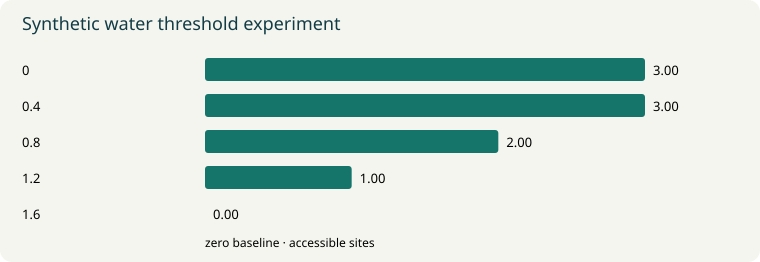

In [2]:
water = [0,.4,.8,1.2,1.6]
roads = [.5,.9,1.3]
floors = [1.1,1.5,1.8]
open_sites = {str(w):sum(w<r and w<f for r,f in zip(roads,floors)) for w in water}
print('Fictional road thresholds:', roads, '; floor thresholds:', floors)
bars(open_sites, 'Synthetic water threshold experiment', 'accessible sites')


## Interpret the result

Road thresholds interrupt access before floors are reached. This bathtub-style comparison has no storm surge, hydraulic connectivity, exposure validation or actual facility portfolio.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Raise floors by 0.5 and then roads by 0.5. Explain why the two interventions may produce different results. What must a real local assessment include?

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Sea-Level-Rise](https://github.com/jltobias/JupyterLite-Sea-Level-Rise).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Sea-Level-Rise/blob/6076bea2c8781285b204a5af0c3cd0ccc5d5ef8e/README.md); inspected 2026-11-01, commit `6076bea2c878`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

Cite Tobias et al.'s AIDS 2024 poster separately. Source's sensitive/provider-governed facility records and report binaries are not distributed here. Anonymized IDs do not make precise facility coordinates open data.

- [Open source learning hub](https://jltobias.github.io/JupyterLite-Sea-Level-Rise/) - Choose among the source project learning experiences. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Read source Book](https://jltobias.github.io/JupyterLite-Sea-Level-Rise/book/intro.html) - Read the original project course and its own source notes. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Run source Lab](https://jltobias.github.io/JupyterLite-Sea-Level-Rise/lite/lab/index.html?path=notebooks/00_start_here.ipynb) - Run the source project notebooks; its dependencies and data terms apply. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Open source explorer](https://jltobias.github.io/JupyterLite-Sea-Level-Rise/dashboard/) - Use the original interactive discovery or teaching explorer. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source terrain scene](https://jltobias.github.io/JupyterLite-Sea-Level-Rise/dashboard/?view=terrain&dataset=synthetic) - Orbit the original conceptual scene; graphics support may be required. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
